In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
                            #===========Task 1.1==================
#Data loader
FILES = {
    "train": "mitbih_train.csv",
    "test": "mitbih_test.csv"
}

def load_raw(data_dir="data"):
    """
    Return {'train': DataFrame, 'test': DataFrame} exactly as stored.
    """

    data_dir = Path(data_dir)

    frames = {}

    for split, name in FILES.items():

        path = data_dir / name

        if not path.exists():
            raise FileNotFoundError(
                f"Missing {path}. Download the dataset first."
            )

        frames[split] = pd.read_csv(path, header=None)

    return frames

raw = load_raw()

for split, df in raw.items():
    print(f"{split}: {df.shape[0]} rows, {df.shape[1]} columns")

print(
    raw["train"].iloc[:3, [0, 1, 2, 185, 186, 187]].to_string()
)

train_df = raw["train"]
test_df = raw["test"]

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

train: 87554 rows, 188 columns
test: 21892 rows, 188 columns
        0         1         2    185  186  187
0  0.977941  0.926471  0.681373  0.0  0.0  0.0
1  0.960114  0.863248  0.461538  0.0  0.0  0.0
2  1.000000  0.659459  0.186486  0.0  0.0  0.0
Training shape: (87554, 188)
Testing shape: (21892, 188)


In [8]:
                 #=============Task 1.2(Seprate signals and labels )==========
X_train = train_df.iloc[:, 0:187]
y_train = train_df.iloc[:, 187]

X_test = test_df.iloc[:, 0:187]
y_test = test_df.iloc[:, 187]

print("Training input shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing input shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

print("Original label data type:", y_train.dtype)
     #===========(Lables into whole Number)============
y_train = y_train.astype(int)
y_test = y_test.astype(int)

print("Training label data type:", y_train.dtype)
print("Testing label data type:", y_test.dtype)

print("Unique training labels:", np.unique(y_train))
print(" Why we convert them? Because our neural network has five classes, represented by integer labels from 0 to 4.")

Training input shape: (87554, 187)
Training labels shape: (87554,)
Testing input shape: (21892, 187)
Testing labels shape: (21892,)
Original label data type: float64
Training label data type: int64
Testing label data type: int64
Unique training labels: [0 1 2 3 4]
 Why we convert them? Because our neural network has five classes, represented by integer labels from 0 to 4.


In [9]:
#===================Task 1.3 (Find minimum and maximum signals values)=========
print("Minimum signal value:", X_train.min().min())

print("Maximum signal value:", X_train.max().max())

Minimum signal value: 0.0
Maximum signal value: 1.0


In [10]:
#=====================Task 1.4 (Converting rows into every class)===============
train_counts = y_train.value_counts().sort_index()

test_counts = y_test.value_counts().sort_index()

print("Training class counts:")
print(train_counts)

print("\nTesting class counts:")
print(test_counts)

#Let's Also printing class names
class_names = [
    "N - Normal",
    "S - Supraventricular",
    "V - Ventricular",
    "F - Fusion",
    "Q - Unknown/Paced"
]

for i in range(5):
    print(class_names[i])
    print("Training:", train_counts[i])
    print("Testing:", test_counts[i])
    print()

Training class counts:
187
0    72471
1     2223
2     5788
3      641
4     6431
Name: count, dtype: int64

Testing class counts:
187
0    18118
1      556
2     1448
3      162
4     1608
Name: count, dtype: int64
N - Normal
Training: 72471
Testing: 18118

S - Supraventricular
Training: 2223
Testing: 556

V - Ventricular
Training: 5788
Testing: 1448

F - Fusion
Training: 641
Testing: 162

Q - Unknown/Paced
Training: 6431
Testing: 1608



In [15]:
import os

saved results/example_beats.png


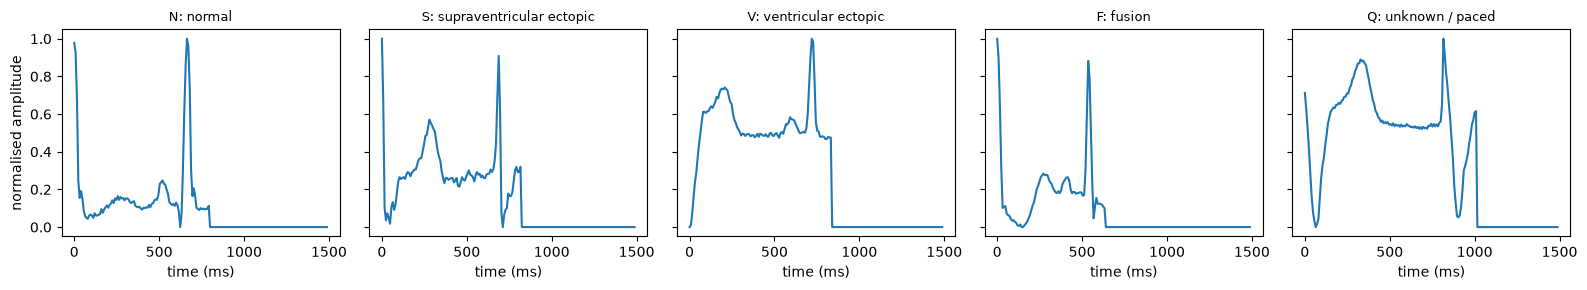

In [16]:
#================== Task 1.5 ==================
CLASS_NAMES = [
    "N: normal",
    "S: supraventricular ectopic",
    "V: ventricular ectopic",
    "F: fusion",
    "Q: unknown / paced"
]

FS = 125

def plot_one_per_class(df, out_path="results/example_beats.png"):

    fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)

    time_ms = [1000 * i / FS for i in range(187)]

    for k, ax in enumerate(axes):

        row = df[df[187] == k].iloc[0]

        ax.plot(time_ms, row.iloc[:187].values)

        ax.set_title(CLASS_NAMES[k], fontsize=9)

        ax.set_xlabel("time (ms)")

    axes[0].set_ylabel("normalised amplitude")

    fig.tight_layout()

    fig.savefig(out_path, dpi=150)

    print(f"saved {out_path}")

    plt.show()


os.makedirs("results", exist_ok=True)

plot_one_per_class(train_df)

In [17]:
#===================Split training data into training and validation (Task 1.6)========
rng = np.random.default_rng(42)

idx = rng.permutation(len(train_df))

n_val = int(0.1 * len(train_df))

val_idx, train_idx = idx[:n_val], idx[n_val:]

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Testing rows:", len(test_df))

Training rows: 78799
Validation rows: 8755
Testing rows: 21892


In [19]:
X_train_tensor = torch.tensor(
    X_train.iloc[train_idx].values,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.iloc[train_idx].values,
    dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_train.iloc[val_idx].values,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_train.iloc[val_idx].values,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test.values,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.long
)

print("Training tensors:")
print(X_train_tensor.shape)
print(y_train_tensor.shape)

print("\nValidation tensors:")
print(X_val_tensor.shape)
print(y_val_tensor.shape)

print("\nTesting tensors:")
print(X_test_tensor.shape)
print(y_test_tensor.shape)

print("\nData types:")
print(X_train_tensor.dtype)
print(y_train_tensor.dtype)


Training tensors:
torch.Size([78799, 187])
torch.Size([78799])

Validation tensors:
torch.Size([8755, 187])
torch.Size([8755])

Testing tensors:
torch.Size([21892, 187])
torch.Size([21892])

Data types:
torch.float32
torch.int64


In [23]:
#=======Create the ECGNet class (Task 2.1)============
class ECGNet(torch.nn.Module):

    def __init__(self):

        super(ECGNet, self).__init__()

        # Layer 1: 187 inputs, 128 neurons
        self.W1 = torch.nn.Parameter(
            torch.randn(128, 187) * np.sqrt(2 / 187)
        )

        self.b1 = torch.nn.Parameter(
            torch.zeros(128)
        )

        # Layer 2: 128 inputs, 64 neurons
        self.W2 = torch.nn.Parameter(
            torch.randn(64, 128) * np.sqrt(2 / 128)
        )

        self.b2 = torch.nn.Parameter(
            torch.zeros(64)
        )

        # Layer 3: 64 inputs, 5 outputs
        self.W3 = torch.nn.Parameter(
            torch.randn(5, 64) * np.sqrt(2 / 64)
        )

        self.b3 = torch.nn.Parameter(
            torch.zeros(5)
        )

    def forward(self, x):

        # First hidden layer
        z1 = x @ self.W1.T + self.b1

        a1 = torch.clamp(z1, min=0)

        # Second hidden layer
        z2 = a1 @ self.W2.T + self.b2

        a2 = torch.clamp(z2, min=0)

        # Output layer
        z3 = a2 @ self.W3.T + self.b3

        return z3

torch.manual_seed(0)

model = ECGNet()

print("ECG Neural Network created successfully!")

ECG Neural Network created successfully!


In [24]:
#==============Test the forward pass (Task 2.3)=========

sample_input = X_train_tensor[:10]

output = model(sample_input)

print("Input shape:", sample_input.shape)

print("Output shape:", output.shape)

print("Output logits:")
print(output)

Input shape: torch.Size([10, 187])
Output shape: torch.Size([10, 5])
Output logits:
tensor([[-0.1796,  1.0583, -0.2440, -0.2660, -0.2863],
        [-0.1349,  1.3647, -0.9500, -0.3305,  0.3714],
        [ 0.0732,  0.3021, -0.1856, -0.1055, -0.0122],
        [ 0.0350,  0.3817, -0.2019,  0.0863, -0.0310],
        [-0.1822,  1.1004, -0.3502, -0.0710, -0.2506],
        [-0.0804,  0.5121, -0.1466, -0.0024,  0.0779],
        [-0.1045,  0.4862, -0.1507, -0.1162,  0.1321],
        [ 0.1128,  0.4371, -0.2818, -0.1838,  0.1227],
        [-0.1506,  0.2256, -0.0220, -0.0118,  0.0623],
        [-0.1105,  0.6919, -0.1305, -0.2206,  0.0206]], grad_fn=<AddBackward0>)


In [25]:
total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 32645


In [27]:
#===================Task 3 (Cross-Entropy Function)=========
def cross_entropy(logits, y):

    batch_size = logits.shape[0]

    correct_class_logits = logits[
        torch.arange(batch_size), y
    ]

    loss = -correct_class_logits + torch.logsumexp(
        logits, dim=1
    )

    return loss.mean()

#Test the loss Function
X_batch = X_train_tensor[:64]

y_batch = y_train_tensor[:64]

logits = model(X_batch)

loss = cross_entropy(logits, y_batch)

print("Batch input shape:", X_batch.shape)

print("Batch label shape:", y_batch.shape)

print("Initial loss:", loss.item())

Batch input shape: torch.Size([64, 187])
Batch label shape: torch.Size([64])
Initial loss: 1.7413432598114014


In [32]:
#=============Calculate Gradient using PyTorch==========
model.zero_grad()

X_batch = X_train_tensor[:64]

y_batch = y_train_tensor[:64]

logits = model(X_batch)

loss = cross_entropy(logits, y_batch)

loss.backward()

print("Loss:", loss.item())

print("PyTorch W3 gradient shape:", model.W3.grad.shape)

print("PyTorch b3 gradient shape:", model.b3.grad.shape)

#First, we calculate the second hidden layer activations.

z1 = X_batch @ model.W1.T + model.b1

a1 = torch.clamp(z1, min=0)

z2 = a1 @ model.W2.T + model.b2

a2 = torch.clamp(z2, min=0)

print("Second hidden layer shape:", a2.shape)

#Now calculate the predicted probabilities and one-hot labels.

Y_hat = torch.softmax(logits.detach(), dim=1)

Y = torch.zeros(64, 5)

Y[torch.arange(64), y_batch] = 1

print("Predicted probabilities shape:", Y_hat.shape)

print("Actual one-hot labels shape:", Y.shape)

#Applying Mathimatical Formulas
B = 64

grad_W3_manual = (Y_hat - Y).T @ a2.detach() / B

grad_b3_manual = (Y_hat - Y).sum(dim=0) / B

print("Manual W3 gradient shape:", grad_W3_manual.shape)

print("Manual b3 gradient shape:", grad_b3_manual.shape)

Loss: 1.7413432598114014
PyTorch W3 gradient shape: torch.Size([5, 64])
PyTorch b3 gradient shape: torch.Size([5])
Second hidden layer shape: torch.Size([64, 64])
Predicted probabilities shape: torch.Size([64, 5])
Actual one-hot labels shape: torch.Size([64, 5])
Manual W3 gradient shape: torch.Size([5, 64])
Manual b3 gradient shape: torch.Size([5])


In [33]:
#=================Compare Both Gradients =================
W3_difference = torch.max(
    torch.abs(grad_W3_manual - model.W3.grad)
)

b3_difference = torch.max(
    torch.abs(grad_b3_manual - model.b3.grad)
)

print("Maximum difference in W3 gradients:", W3_difference.item())

print("Maximum difference in b3 gradients:", b3_difference.item())

Maximum difference in W3 gradients: 1.4901161193847656e-08
Maximum difference in b3 gradients: 5.960464477539063e-08


In [37]:
#===================Task 4.1 Write train(alpha)===================
def train(alpha):

    torch.manual_seed(0)

    model = ECGNet()

    batch_size = 128
    beta = 0.9
    weight_decay = 1e-4
    epochs = 30

    velocities = {}

    for name, param in model.named_parameters():
        velocities[name] = torch.zeros_like(param)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        model.train()

        permutation = torch.randperm(len(X_train_tensor))

        for start in range(0, len(X_train_tensor), batch_size):

            indices = permutation[start:start + batch_size]

            xb = X_train_tensor[indices]
            yb = y_train_tensor[indices]

            model.zero_grad()

            logits = model(xb)

            loss = cross_entropy(logits, yb)

            loss.backward()

            with torch.no_grad():

                for name, param in model.named_parameters():

                    gradient = param.grad

                    if name.startswith("W"):
                        gradient = gradient + weight_decay * param

                    velocities[name].mul_(beta).add_(
                        gradient, alpha=(1 - beta)
                    )

                    param.sub_(alpha * velocities[name])

        model.eval()

        with torch.no_grad():

            train_logits = model(X_train_tensor)
            train_loss = cross_entropy(
                train_logits, y_train_tensor
            ).item()

            train_predictions = torch.argmax(
                train_logits, dim=1
            )

            train_accuracy = (
                train_predictions == y_train_tensor
            ).float().mean().item()

            val_logits = model(X_val_tensor)
            val_loss = cross_entropy(
                val_logits, y_val_tensor
            ).item()

            val_predictions = torch.argmax(
                val_logits, dim=1
            )

            val_accuracy = (
                val_predictions == y_val_tensor
            ).float().mean().item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                name: param.detach().clone()
                for name, param in model.state_dict().items()
            }

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    return model, history, best_state, best_val_loss, best_epoch

In [38]:
#====================Task 4.2 (Test the three learning rates)============
learning_rates = [0.01, 0.1, 0.5]

results_by_alpha = {}

for alpha in learning_rates:

    print("\nTraining with learning rate:", alpha)

    model, history, best_state, best_val_loss, best_epoch = train(alpha)

    results_by_alpha[alpha] = {
        "model": model,
        "history": history,
        "best_state": best_state,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    }

    print("Best validation loss:", best_val_loss)
    print("Best epoch:", best_epoch)


Training with learning rate: 0.01
Epoch 01/30 | Train Loss: 0.4651 | Val Loss: 0.4612 | Train Accuracy: 0.8671 | Val Accuracy: 0.8675
Epoch 02/30 | Train Loss: 0.3869 | Val Loss: 0.3825 | Train Accuracy: 0.8936 | Val Accuracy: 0.8948
Epoch 03/30 | Train Loss: 0.3468 | Val Loss: 0.3420 | Train Accuracy: 0.9074 | Val Accuracy: 0.9083
Epoch 04/30 | Train Loss: 0.3187 | Val Loss: 0.3145 | Train Accuracy: 0.9149 | Val Accuracy: 0.9147
Epoch 05/30 | Train Loss: 0.2979 | Val Loss: 0.2942 | Train Accuracy: 0.9213 | Val Accuracy: 0.9218
Epoch 06/30 | Train Loss: 0.2804 | Val Loss: 0.2766 | Train Accuracy: 0.9242 | Val Accuracy: 0.9255
Epoch 07/30 | Train Loss: 0.2665 | Val Loss: 0.2636 | Train Accuracy: 0.9273 | Val Accuracy: 0.9272
Epoch 08/30 | Train Loss: 0.2545 | Val Loss: 0.2510 | Train Accuracy: 0.9297 | Val Accuracy: 0.9294
Epoch 09/30 | Train Loss: 0.2440 | Val Loss: 0.2414 | Train Accuracy: 0.9331 | Val Accuracy: 0.9323
Epoch 10/30 | Train Loss: 0.2353 | Val Loss: 0.2329 | Train Accur

In [39]:
print("Learning Rate Comparison")
print("------------------------")

for alpha in learning_rates:

    best_loss = results_by_alpha[alpha]["best_val_loss"]
    best_epoch = results_by_alpha[alpha]["best_epoch"]

    print(
        f"Learning Rate: {alpha} | "
        f"Best Validation Loss: {best_loss:.4f} | "
        f"Best Epoch: {best_epoch}"
    )

Learning Rate Comparison
------------------------
Learning Rate: 0.01 | Best Validation Loss: 0.1618 | Best Epoch: 30
Learning Rate: 0.1 | Best Validation Loss: 0.0857 | Best Epoch: 28
Learning Rate: 0.5 | Best Validation Loss: 0.0729 | Best Epoch: 23


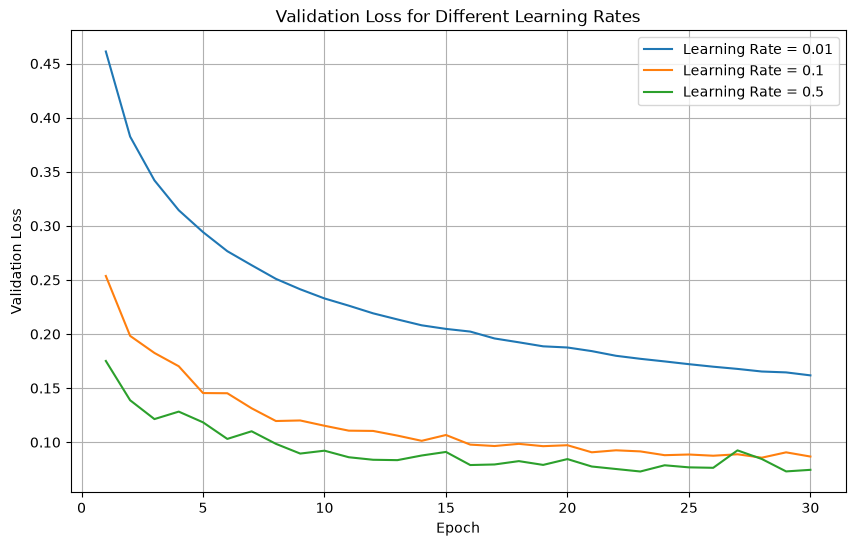

In [44]:
plt.figure(figsize=(10, 6))

for alpha in learning_rates:

    val_losses = results_by_alpha[alpha]["history"]["val_loss"]

    plt.plot(
        range(1, 31),
        val_losses,
        label=f"Learning Rate = {alpha}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss for Different Learning Rates")
plt.legend()
plt.grid(True)

plt.savefig("results/learning_rate_comparison.png", dpi=150)

plt.show()



In [47]:
#Automatically Select learning Rate
chosen_alpha = min(
    learning_rates,
    key=lambda alpha: results_by_alpha[alpha]["best_val_loss"]
)

print("Selected Learning Rate:", chosen_alpha)

print(
    "Lowest Validation Loss:",
    results_by_alpha[chosen_alpha]["best_val_loss"]
)

print(
    "Best Epoch:",
    results_by_alpha[chosen_alpha]["best_epoch"]
)

Selected Learning Rate: 0.5
Lowest Validation Loss: 0.07293866574764252
Best Epoch: 23


In [48]:
#====================Taks 4.3( Plot curves and save the best model)=====
selected_model = results_by_alpha[chosen_alpha]["model"]

best_state = results_by_alpha[chosen_alpha]["best_state"]

selected_model.load_state_dict(best_state)

print("Best model restored successfully.")

Best model restored successfully.


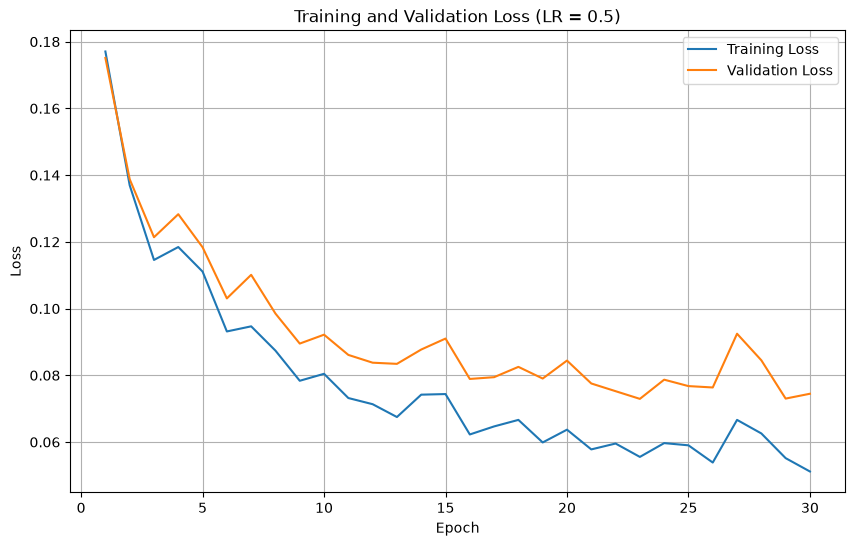

In [49]:
#Plot training and validation loss
best_history = results_by_alpha[chosen_alpha]["history"]

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 31),
    best_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    range(1, 31),
    best_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Training and Validation Loss (LR = {chosen_alpha})")
plt.legend()
plt.grid(True)

plt.savefig("results/training_validation_loss.png", dpi=150)

plt.show()

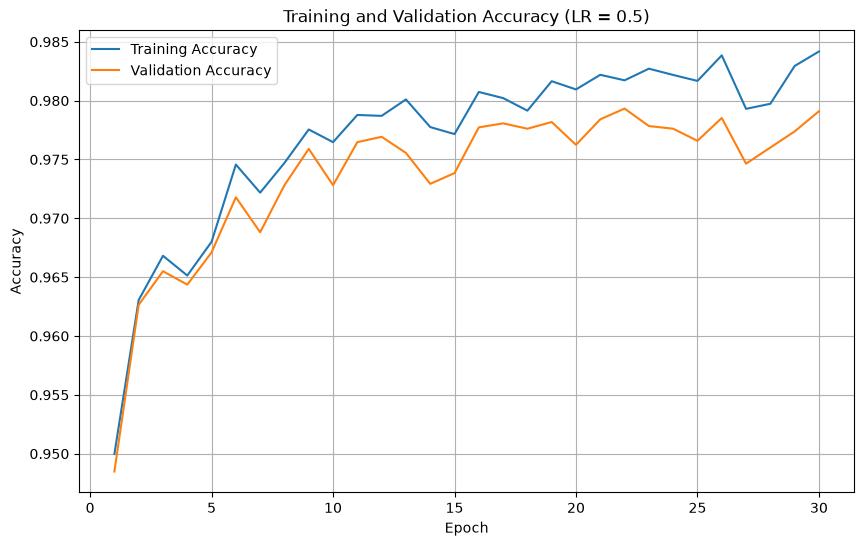

In [50]:
#Plot training and valdation accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 31),
    best_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    range(1, 31),
    best_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Training and Validation Accuracy (LR = {chosen_alpha})")
plt.legend()
plt.grid(True)

plt.savefig("results/training_validation_accuracy.png", dpi=150)

plt.show()

In [51]:
#Save the best model
torch.save(
    selected_model.state_dict(),
    "results/best_model.pth"
)

print("Best model saved successfully.")
print("File: results/best_model.pth")

Best model saved successfully.
File: results/best_model.pth


In [53]:
#================Task 5 (Evaluate the Model on Test Data)===============
test_model = ECGNet()

test_model.load_state_dict(
    torch.load("results/best_model.pth", map_location="cpu")
)

test_model.eval()

print("Best trained model loaded successfully.")

with torch.no_grad():

    test_logits = test_model(X_test_tensor)

    test_predictions = torch.argmax(test_logits, dim=1)

print("Test predictions generated successfully.")
print("Number of test predictions:", len(test_predictions))
print("Number of actual labels:", len(y_test_tensor))

Best trained model loaded successfully.
Test predictions generated successfully.
Number of test predictions: 21892
Number of actual labels: 21892


In [54]:
#Calulate overall test accuracy
correct_predictions = (
    test_predictions == y_test_tensor
).sum().item()

total_predictions = len(y_test_tensor)

test_accuracy = correct_predictions / total_predictions

print("Correct Predictions:", correct_predictions)
print("Total Predictions:", total_predictions)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Correct Predictions: 21399
Total Predictions: 21892
Test Accuracy: 0.9774803581216883
Test Accuracy (%): 97.74803581216884


Confusion Matrix:
tensor([[18029,    27,    16,    10,    36],
        [  168,   379,     6,     0,     3],
        [  104,     4,  1317,    14,     9],
        [   39,     0,    21,   101,     1],
        [   29,     2,     4,     0,  1573]])
confusion Matrix as Graph


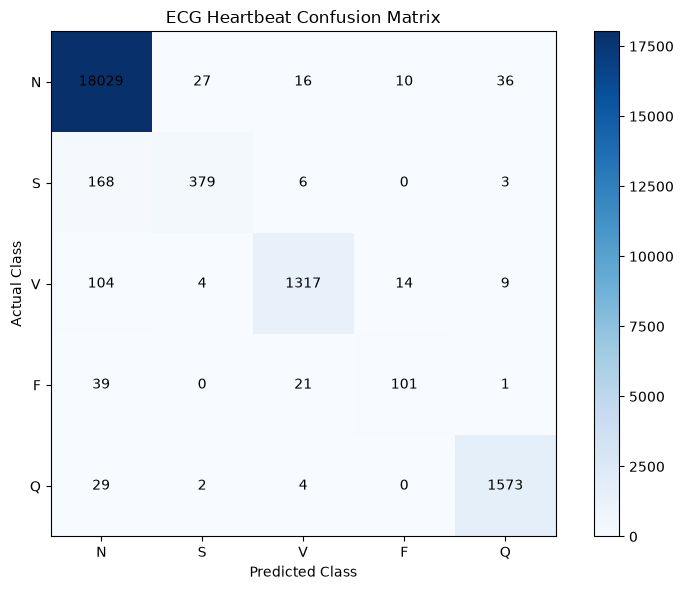

In [56]:
#Confusion matrix
confusion_matrix = torch.zeros(
    (5, 5), dtype=torch.int64
)

for i in range(len(y_test_tensor)):

    actual = y_test_tensor[i].item()
    predicted = test_predictions[i].item()

    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

print ("confusion Matrix as Graph")
plt.figure(figsize=(8, 6))

plt.imshow(confusion_matrix.numpy(), cmap="Blues")

plt.title("ECG Heartbeat Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5), ["N", "S", "V", "F", "Q"])
plt.yticks(range(5), ["N", "S", "V", "F", "Q"])

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i,
            str(confusion_matrix[i, j].item()),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

In [59]:
#Calculate per class accuracy
class_names = [
    "N: Normal",
    "S: Supraventricular",
    "V: Ventricular",
    "F: Fusion",
    "Q: Unknown/Paced"
]

class_accuracies = []

for k in range(5):

    correct = confusion_matrix[k, k].item()

    total = confusion_matrix[k].sum().item()

    accuracy = correct / total

    class_accuracies.append(accuracy)

    print(
        class_names[k],
        "Accuracy:",
        round(accuracy * 100, 2),
        "%"
    )

print("Calculating Balanced Accuracy")

balanced_accuracy = sum(class_accuracies) / 5

print("Balanced Accuracy:", balanced_accuracy)
print("Balanced Accuracy (%):", balanced_accuracy * 100)

N: Normal Accuracy: 99.51 %
S: Supraventricular Accuracy: 68.17 %
V: Ventricular Accuracy: 90.95 %
F: Fusion Accuracy: 62.35 %
Q: Unknown/Paced Accuracy: 97.82 %
Calculating Balanced Accuracy
Balanced Accuracy: 0.8375926883998479
Balanced Accuracy (%): 83.75926883998478


In [60]:
#Saving the confusion matrix and results
import pandas as pd

cm_df = pd.DataFrame(
    confusion_matrix.numpy(),
    index=["N", "S", "V", "F", "Q"],
    columns=["N", "S", "V", "F", "Q"]
)

cm_df.to_csv("results/confusion_matrix.csv")

results_df = pd.DataFrame({
    "Class": class_names,
    "Accuracy (%)": [
        accuracy * 100 for accuracy in class_accuracies
    ]
})

results_df.to_csv(
    "results/per_class_accuracy.csv",
    index=False
)

print("Task 5 results saved successfully.")

Task 5 results saved successfully.


In [2]:
import os

In [3]:
for folder in ["src", "results", "data", "app"]:
    print(f"\n{folder}:")

    if os.path.exists(folder):
        for item in os.listdir(folder):
            print("  ", item)
    else:
        print("   Folder does not exist")


src:
   grad_check.py
   load_data.py
   metrics.py
   model.py
   plot_beats.py
   prepare.py
   test_model.py
   train.py
   __init__.py

results:
   .ipynb_checkpoints
   analysis.md
   best_model.pth
   confusion_matrix.csv
   confusion_matrix.png
   example_beats.png
   learning_rate_comparison.png
   per_class_accuracy.csv
   training_validation_accuracy.png
   training_validation_loss.png

data:
   mitbih_test.csv
   mitbih_train.csv

app:


In [6]:
!python -m src.load_data

train: 87554 rows, 188 columns
test: 21892 rows, 188 columns
        0         1         2    185  186  187
0  0.977941  0.926471  0.681373  0.0  0.0  0.0
1  0.960114  0.863248  0.461538  0.0  0.0  0.0
2  1.000000  0.659459  0.186486  0.0  0.0  0.0


In [7]:
!python -m src.plot_beats

saved results/example_beats.png
Figure(1600x300)


In [8]:
!python -m src.prepare

Training shape: (87554, 188)
Testing shape: (21892, 188)
Training input shape: (87554, 187)
Training labels shape: (87554,)
Testing input shape: (21892, 187)
Testing labels shape: (21892,)
Minimum signal value: 0.0
Maximum signal value: 1.0

Class counts:
N - Normal
Training: 72471
Testing: 18118
S - Supraventricular
Training: 2223
Testing: 556
V - Ventricular
Training: 5788
Testing: 1448
F - Fusion
Training: 641
Testing: 162
Q - Unknown/Paced
Training: 6431
Testing: 1608

Training rows: 78799
Validation rows: 8755
Testing rows: 21892

Tensor shapes:
Train: torch.Size([78799, 187]) torch.Size([78799])
Validation: torch.Size([8755, 187]) torch.Size([8755])
Test: torch.Size([21892, 187]) torch.Size([21892])


In [9]:
!python -m src.model

ECG Neural Network created successfully!
Total trainable parameters: 32645


In [10]:
!python -m src.grad_check

Training shape: (87554, 188)
Testing shape: (21892, 188)
Training input shape: (87554, 187)
Training labels shape: (87554,)
Testing input shape: (21892, 187)
Testing labels shape: (21892,)
Minimum signal value: 0.0
Maximum signal value: 1.0

Class counts:
N - Normal
Training: 72471
Testing: 18118
S - Supraventricular
Training: 2223
Testing: 556
V - Ventricular
Training: 5788
Testing: 1448
F - Fusion
Training: 641
Testing: 162
Q - Unknown/Paced
Training: 6431
Testing: 1608

Training rows: 78799
Validation rows: 8755
Testing rows: 21892

Tensor shapes:
Train: torch.Size([78799, 187]) torch.Size([78799])
Validation: torch.Size([8755, 187]) torch.Size([8755])
Test: torch.Size([21892, 187]) torch.Size([21892])
Loss: 1.7413432598114014
Manual W3 gradient shape: torch.Size([5, 64])
Manual b3 gradient shape: torch.Size([5])
Maximum difference in W3 gradients: 1.4901161193847656e-08
Maximum difference in b3 gradients: 5.960464477539063e-08
Gradient check passed.


In [11]:
!python -m src.train

Training shape: (87554, 188)
Testing shape: (21892, 188)
Training input shape: (87554, 187)
Training labels shape: (87554,)
Testing input shape: (21892, 187)
Testing labels shape: (21892,)
Minimum signal value: 0.0
Maximum signal value: 1.0

Class counts:
N - Normal
Training: 72471
Testing: 18118
S - Supraventricular
Training: 2223
Testing: 556
V - Ventricular
Training: 5788
Testing: 1448
F - Fusion
Training: 641
Testing: 162
Q - Unknown/Paced
Training: 6431
Testing: 1608

Training rows: 78799
Validation rows: 8755
Testing rows: 21892

Tensor shapes:
Train: torch.Size([78799, 187]) torch.Size([78799])
Validation: torch.Size([8755, 187]) torch.Size([8755])
Test: torch.Size([21892, 187]) torch.Size([21892])

Training with learning rate: 0.01
Epoch 01/30 | Train Loss: 0.4651 | Val Loss: 0.4612 | Train Accuracy: 0.8671 | Val Accuracy: 0.8675
Epoch 02/30 | Train Loss: 0.3869 | Val Loss: 0.3825 | Train Accuracy: 0.8936 | Val Accuracy: 0.8948
Epoch 03/30 | Train Loss: 0.3468 | Val Loss: 0.342

In [12]:
!python -m src.test_model

Training shape: (87554, 188)
Testing shape: (21892, 188)
Training input shape: (87554, 187)
Training labels shape: (87554,)
Testing input shape: (21892, 187)
Testing labels shape: (21892,)
Minimum signal value: 0.0
Maximum signal value: 1.0

Class counts:
N - Normal
Training: 72471
Testing: 18118
S - Supraventricular
Training: 2223
Testing: 556
V - Ventricular
Training: 5788
Testing: 1448
F - Fusion
Training: 641
Testing: 162
Q - Unknown/Paced
Training: 6431
Testing: 1608

Training rows: 78799
Validation rows: 8755
Testing rows: 21892

Tensor shapes:
Train: torch.Size([78799, 187]) torch.Size([78799])
Validation: torch.Size([8755, 187]) torch.Size([8755])
Test: torch.Size([21892, 187]) torch.Size([21892])
Test predictions generated: 21892
Correct predictions: 21399
Total predictions: 21892
Test accuracy: 0.9774803519248962
Test accuracy (%): 97.74803519248962

Confusion Matrix (rows=true, columns=predicted):
tensor([[18029,    27,    16,    10,    36],
        [  168,   379,     6,    

In [ ]:
!streamlit run app/app.py